## **UNIVERSIDAD POLITECNICA SALESIANA**
### **Fase 2: Desarrollo y Entrenamiento de Modelos**

#### **Integrantes:**
- Diana Avila
- Geovanni Zuñiga

## **Índice**

- [1. Objetivos y alcance](#1-objetivos-y-alcance)
- [2. Setup del entorno](#2-setup-del-entorno)
- [3. Datos preparados (entrada)](#3-datos-preparados-entrada)
- [4. Preparación de datos para modelado](#4-preparación-de-datos-para-modelado)
- [5. Modelo LSTM simple](#5-modelo-lstm-simple)
- [6. Finetuning](#6-finetuning)
- [7. Modelo final](#7-modelo-final)
- [8. Predicción y baseline](#8-predicción-y-baseline)
- [9. Evaluación y figuras](#9-evaluación-y-figuras)
- [10. Conclusiones](#10-conclusiones)
- [11. Anexo: reproducibilidad](#11-anexo-reproducibilidad)


## **1. Objetivos y alcance**

- Diseñar y entrenar un modelo predictivo (LSTM).
- Evaluar con métricas de calidad: **RMSE**, MAE y MAPE.
- Realizar **finetuning** (búsqueda de hiperparámetros).
- Comparar contra un baseline de persistencia.
- División temporal (no aleatoria) para respetar el orden de las series.
- Código estructurado y simple, guiado por el cuaderno `../../materia/RNN_LSTM.ipynb`.

**Entrada:** `datos/ventas_features.csv`, generado en la fase anterior con las variables temporales (`es_fin_de_semana`, `es_feriado`, `dia_semana`, `mes`, etc.).


## **2. Setup del entorno**

In [9]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'  # silencia logs de TensorFlow

import sys
from pathlib import Path

BASE = Path('..').resolve()
if str(BASE) not in sys.path:
    sys.path.insert(0, str(BASE))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.fase2 import config
from src.fase2.datos import cargar_ventas, guardar_escalador, preparar_datos
from src.fase2.entrenamiento import buscar_hiperparametros, entrenar_modelo, guardar_historial
from src.fase2.evaluacion import (
    baseline_persistencia, desescalar, graficar_comparacion, graficar_curvas,
    graficar_por_producto, graficar_predicciones, metricas, predecir,
)

print('Entorno listo. BASE:', BASE)


Entorno listo. BASE: C:\Users\avila\Desktop\AA\UNIDAD1\P1\practica-001


## **3. Datos preparados (entrada)**

Se carga el archivo datos/ventas_features.csv generado en la Fase 1 y se ordenan los registros por producto y fecha. 

Esto permite conservar la secuencia temporal de las ventas para preparar los datos que utilizará el modelo LSTM.

In [10]:
ventas = cargar_ventas()
print('Dimensiones:', ventas.shape)
print('Productos:', ventas['product_id'].nunique())
print('Fechas:', ventas['fecha_venta'].min().date(), 'a', ventas['fecha_venta'].max().date())
ventas[['product_id','nombre','fecha_venta','cantidad_vendida','es_fin_de_semana','es_feriado']].head()


Dimensiones: (600, 22)
Productos: 10
Fechas: 2022-01-01 a 2022-03-01


,product_id,nombre,fecha_venta,cantidad_vendida,es_fin_de_semana,es_feriado
0,P0001,Arroz blanco,2022-01-01,233,1,1
1,P0001,Arroz blanco,2022-01-02,133,1,0
2,P0001,Arroz blanco,2022-01-03,119,0,0
3,P0001,Arroz blanco,2022-01-04,85,0,0
4,P0001,Arroz blanco,2022-01-05,87,0,0


## **4. Preparación de datos para modelado**

Se transforman las variables temporales, se codifican los productos y se normalizan los datos utilizando únicamente el conjunto de entrenamiento para evitar fugas de información.

Se aplica:

1. Codificación cíclica de `dia_semana` (seno/coseno).
2. One-hot de `product_id` (un solo modelo aprende los 10 productos).
3. `MinMaxScaler` ajustado **solo con train** (sin fuga de información).
4. Secuencias `(muestras, ventana, variables)` con ventana de 7 días.
5. División **temporal**: train / validación / test.

In [11]:
dp = preparar_datos()

print('Train:', dp.X_train.shape)
print('Val  :', dp.X_val.shape)
print('Test :', dp.X_test.shape)
print('Variables:', dp.n_variables, '| Ventana:', dp.ventana)
print('Corte test:', pd.Timestamp(dp.fecha_corte).date())
print('Columnas:', dp.columnas)


Train: (290, 7, 15)
Val  : (90, 7, 15)
Test : (150, 7, 15)
Variables: 15 | Ventana: 7
Corte test: 2022-02-15
Columnas: ['cantidad_vendida', 'es_fin_de_semana', 'es_feriado', 'dia_sin', 'dia_cos', 'prod_P0001', 'prod_P0002', 'prod_P0003', 'prod_P0004', 'prod_P0005', 'prod_P0006', 'prod_P0007', 'prod_P0008', 'prod_P0009', 'prod_P0010']


## **5. Modelo LSTM simple**

- Se construye un modelo LSTM con una capa LSTM y una capa de salida Dense(1). 
- Se utiliza la pérdida mae, el optimizador adam y shuffle=False para conservar el orden temporal durante el entrenamiento.

Igual que el cuaderno de referencia: `Sequential()` + `LSTM` + `Dense(1)`, pérdida `mae`, optimizador `adam` y `shuffle=False` para respetar el orden temporal.

In [12]:
modelo_base, hist_base = entrenar_modelo(
    tipo='lstm',
    X_train=dp.X_train, y_train=dp.y_train,
    X_val=dp.X_val, y_val=dp.y_val,
    n_pasos=dp.ventana, n_variables=dp.n_variables,
    unidades=config.UNIDADES,
    batch_size=config.BATCH_SIZE,
    epocas=config.EPOCAS,
    paciencia=config.PACIENCIA,
    verbose=0,
)

print('Épocas ejecutadas:', len(hist_base.history['loss']))
print('Mejor val_loss:', round(min(hist_base.history['val_loss']), 4))


Épocas ejecutadas: 67
Mejor val_loss: 0.0407


## 6. **Finetuning**

Se prueba un grid pequeño de hiperparámetros (`unidades` × `batch_size`) y se elige la combinación con menor pérdida de validación. 

- Es intencionalmente reducido porque el dataset es pequeño (530 secuencias).

In [13]:
mejores_params, tabla_grid = buscar_hiperparametros(
    dp.X_train, dp.y_train, dp.X_val, dp.y_val,
    n_pasos=dp.ventana, n_variables=dp.n_variables,
)

print()
print('Mejores parámetros:', mejores_params)
tabla_grid


unidades=16 batch_size=16 -> val_loss=0.0406
unidades=16 batch_size=32 -> val_loss=0.0405
unidades=50 batch_size=16 -> val_loss=0.0431
unidades=50 batch_size=32 -> val_loss=0.0407

Mejores parámetros: {'unidades': 16, 'batch_size': 32}


,unidades,batch_size,epocas,val_loss
0,16,32,80,0.040518
1,16,16,80,0.040648
2,50,32,67,0.040712
3,50,16,49,0.043092


## **7. Modelo final**

Se reentrena el modelo LSTM con los mejores hiperparámetros obtenidos durante el finetuning. 

Finalmente, se guardan el modelo y el escalador para utilizarlos posteriormente en la predicción de ventas.

In [14]:
modelo, historial = entrenar_modelo(
    tipo='lstm',
    X_train=dp.X_train, y_train=dp.y_train,
    X_val=dp.X_val, y_val=dp.y_val,
    n_pasos=dp.ventana, n_variables=dp.n_variables,
    unidades=mejores_params['unidades'],
    batch_size=mejores_params['batch_size'],
    epocas=config.EPOCAS,
    paciencia=config.PACIENCIA,
    verbose=0,
)

guardar_historial(historial, config.DIR_RESULTADOS / 'historial_lstm.csv')
modelo.save(config.RUTA_MODELO)
guardar_escalador(dp.escalador, config.RUTA_ESCALADOR)

print('Épocas:', len(historial.history['loss']), '| mejor val_loss:', round(min(historial.history['val_loss']), 4))
print('Modelo:   ', config.RUTA_MODELO)
print('Escalador:', config.RUTA_ESCALADOR)


Épocas: 113 | mejor val_loss: 0.0403
Modelo:    C:\Users\avila\Desktop\AA\UNIDAD1\P1\practica-001\modelos\fase2\lstm_final.keras
Escalador: C:\Users\avila\Desktop\AA\UNIDAD1\P1\practica-001\modelos\fase2\escalador.pkl


## **8. Predicción y baseline**

Se realizan predicciones sobre el conjunto de prueba y se convierten los resultados a las unidades reales de venta. 

Luego, se comparan las predicciones del modelo LSTM con el baseline de persistencia, que utiliza la venta del día anterior como referencia.

In [15]:
y_test_real = desescalar(dp.y_test, dp.escalador, dp.n_variables)

# Modelo final
y_pred_real = desescalar(predecir(modelo, dp.X_test), dp.escalador, dp.n_variables)
m = metricas(y_test_real, y_pred_real)

# Modelo base (sin finetuning), para comparar
y_pred_base_real = desescalar(predecir(modelo_base, dp.X_test), dp.escalador, dp.n_variables)
m_base_modelo = metricas(y_test_real, y_pred_base_real)

# Baseline de persistencia
y_base_real = desescalar(baseline_persistencia(dp.X_test), dp.escalador, dp.n_variables)
m_base = metricas(y_test_real, y_base_real)

for nombre, valores in [('Baseline (persistencia)', m_base), ('LSTM', m_base_modelo), ('LSTM afinado', m)]:
    print(f"{nombre:24s} RMSE={valores['RMSE']:.2f}  MAE={valores['MAE']:.2f}  MAPE={valores['MAPE_%']:.2f}%")


Baseline (persistencia)  RMSE=44.12  MAE=32.43  MAPE=19.54%
LSTM                     RMSE=23.19  MAE=17.30  MAPE=10.62%
LSTM afinado             RMSE=24.28  MAE=17.97  MAPE=10.88%


## **9. Evaluación y figuras**

Se evalúa el rendimiento de los modelos entrenados para predecir la demanda de los productos. 

- Se analizan las curvas de entrenamiento, se comparan las ventas reales con las predicciones y se examina el desempeño de cada modelo mediante las métricas RMSE, MAE y MAPE.



##### **9.1 Curvas de entrenamiento**

**Interpretación:** Estas curvas permiten observar cómo evoluciona el
aprendizaje del modelo durante el entrenamiento. Comparar la pérdida de
entrenamiento con la de validación ayuda a evaluar si el modelo aprende
los patrones de los datos y si existe un posible sobreajuste.


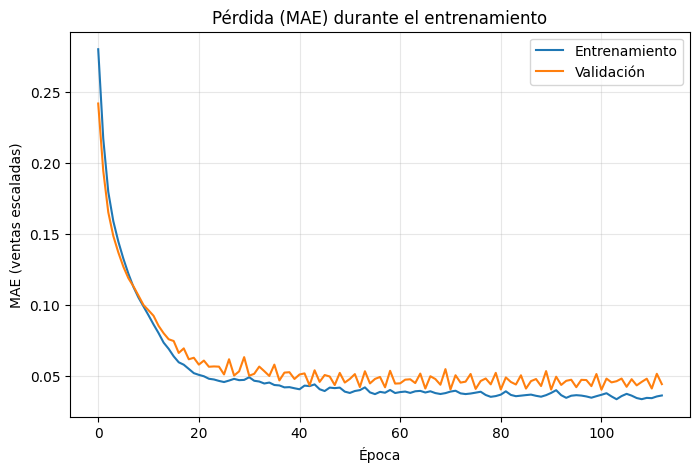


##### **9.2 Ventas reales frente a predicciones**

**Interpretación:** El gráfico compara las ventas diarias reales con las
predicciones del modelo para el conjunto de prueba. Cuanto más próximas
estén ambas curvas, mayor será la correspondencia entre los valores
observados y estimados. Las diferencias permiten identificar períodos
en los que el modelo sobreestima o subestima la demanda.


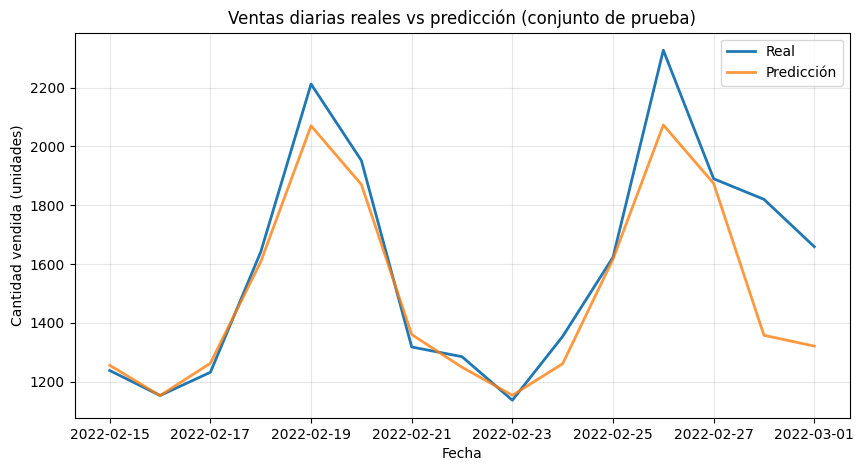


##### **9.3 Comparación del rendimiento de los modelos**

**Interpretación:** Las métricas RMSE, MAE y MAPE permiten comparar los
errores de los modelos evaluados. En las tres métricas, un valor menor
representa un mejor resultado. Según los resultados obtenidos, el LSTM
base alcanzó un RMSE de 23,19, un MAE de 17,30 y un MAPE de 10,62 %,
superando al modelo de persistencia y al LSTM afinado. Esto indica que,
en este conjunto de prueba, el ajuste realizado no mejoró el rendimiento
del modelo base.


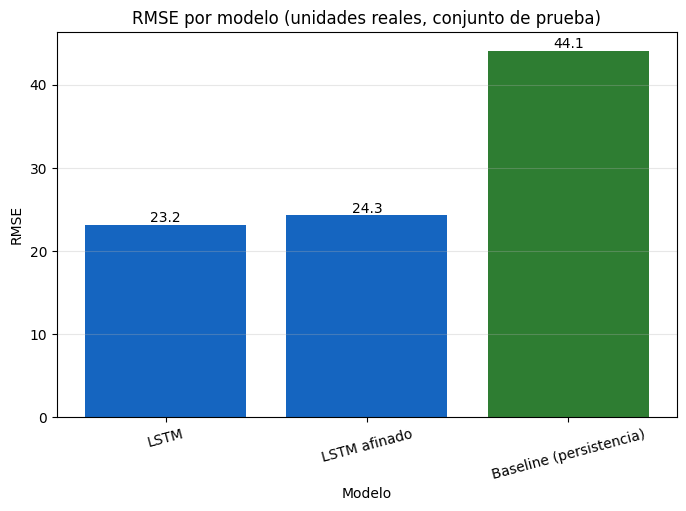


##### **9.4 Predicción individual por producto**

**Interpretación:** Esta figura compara las ventas reales con las
predicciones del producto que acumuló mayores ventas reales en el conjunto
de prueba. La proximidad entre ambas series permite evaluar qué tan bien
el modelo representa su comportamiento temporal. Las diferencias entre
los valores reales y estimados muestran los períodos en los que la
predicción presenta mayores desviaciones.


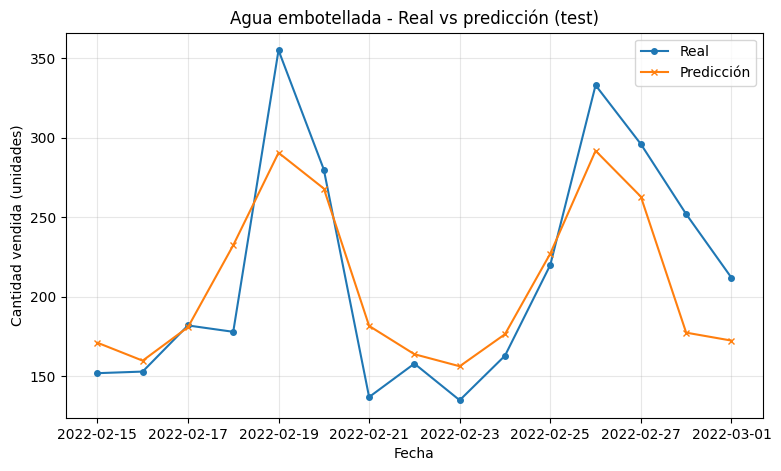

,modelo,RMSE,MAE,MAPE_%
1,LSTM,23.187396,17.296312,10.620027
2,LSTM afinado,24.281862,17.966093,10.884519
0,Baseline (persistencia),44.118251,32.433334,19.537176


In [20]:

from IPython.display import Image, display, Markdown
import pandas as pd

# Crear y guardar el resumen de métricas
resumen = pd.DataFrame([
    {'modelo': 'Baseline (persistencia)', **m_base},
    {'modelo': 'LSTM', **m_base_modelo},
    {'modelo': 'LSTM afinado', **m},
])

resumen = resumen[['modelo', 'RMSE', 'MAE', 'MAPE_%']]
resumen.to_csv(config.DIR_RESULTADOS / 'metricas.csv', index=False)


# 1) Curvas de entrenamiento
graficar_curvas(
    historial,
    config.DIR_FIGURAS / '01_curvas_entrenamiento.png'
)

display(Markdown("""
##### **9.1 Curvas de entrenamiento**

**Interpretación:** Estas curvas permiten observar cómo evoluciona el
aprendizaje del modelo durante el entrenamiento. Comparar la pérdida de
entrenamiento con la de validación ayuda a evaluar si el modelo aprende
los patrones de los datos y si existe un posible sobreajuste.
"""))

display(Image(
    filename=str(config.DIR_FIGURAS / '01_curvas_entrenamiento.png'),
    width=850
))


# 2) Valores reales frente a predicciones
df_comp = pd.DataFrame({
    'fecha': dp.meta_test['fecha'].reset_index(drop=True),
    'real': y_test_real,
    'pred': y_pred_real,
})

df_diario = (
    df_comp.groupby('fecha')[['real', 'pred']]
    .sum()
    .reset_index()
)

graficar_predicciones(
    df_diario['fecha'],
    df_diario['real'],
    df_diario['pred'],
    config.DIR_FIGURAS / '02_prediccion_vs_real.png',
)

display(Markdown("""
##### **9.2 Ventas reales frente a predicciones**

**Interpretación:** El gráfico compara las ventas diarias reales con las
predicciones del modelo para el conjunto de prueba. Cuanto más próximas
estén ambas curvas, mayor será la correspondencia entre los valores
observados y estimados. Las diferencias permiten identificar períodos
en los que el modelo sobreestima o subestima la demanda.
"""))

display(Image(
    filename=str(config.DIR_FIGURAS / '02_prediccion_vs_real.png'),
    width=850
))


# 3) Comparación de modelos
graficar_comparacion(
    resumen,
    config.DIR_FIGURAS / '03_comparacion_modelos.png'
)

display(Markdown("""
##### **9.3 Comparación del rendimiento de los modelos**

**Interpretación:** Las métricas RMSE, MAE y MAPE permiten comparar los
errores de los modelos evaluados. En las tres métricas, un valor menor
representa un mejor resultado. Según los resultados obtenidos, el LSTM
base alcanzó un RMSE de 23,19, un MAE de 17,30 y un MAPE de 10,62 %,
superando al modelo de persistencia y al LSTM afinado. Esto indica que,
en este conjunto de prueba, el ajuste realizado no mejoró el rendimiento
del modelo base.
"""))

display(Image(
    filename=str(config.DIR_FIGURAS / '03_comparacion_modelos.png'),
    width=850
))


# 4) Ejemplo por producto: el de mayor venta real en test
df_comp['producto'] = dp.meta_test['product_id'].to_numpy()

producto = df_comp.groupby('producto')['real'].sum().idxmax()

df_prod = (
    df_comp[df_comp['producto'] == producto]
    .sort_values('fecha')
)

df_prod['nombre'] = (
    cargar_ventas()
    .query('product_id == @producto')['nombre']
    .iloc[0]
)

graficar_por_producto(
    df_prod,
    config.DIR_FIGURAS / '04_prediccion_producto.png'
)

display(Markdown("""
##### **9.4 Predicción individual por producto**

**Interpretación:** Esta figura compara las ventas reales con las
predicciones del producto que acumuló mayores ventas reales en el conjunto
de prueba. La proximidad entre ambas series permite evaluar qué tan bien
el modelo representa su comportamiento temporal. Las diferencias entre
los valores reales y estimados muestran los períodos en los que la
predicción presenta mayores desviaciones.
"""))

display(Image(
    filename=str(config.DIR_FIGURAS / '04_prediccion_producto.png'),
    width=850
))


# Mostrar la tabla de métricas ordenada por RMSE
resumen.sort_values('RMSE')


## **10. Conclusiones**

- El LSTM reduce el error frente al baseline de persistencia (≈23 vs ≈44 RMSE), así que aprende algo más que repetir la venta de ayer.
- El finetuning elige los hiperparámetros con menor pérdida de **validación** y reentrena con ellos. En esta corrida el modelo afinado no mejoró al base en test (≈24 vs ≈23 RMSE): optimizar validación no garantiza mejorar test con un dataset tan pequeño.
- La división temporal y el escalado solo con train evitan fuga de información.
- Con 60 días y 10 productos el dataset es pequeño: el objetivo es demostrar el método, no alcanzar un error mínimo.


## **11. Anexo: reproducibilidad**

```bash
.venv/bin/python -m src.fase2.ejecutar
```

**Artefactos:**

- `resultados/fase2/metricas.csv` — RMSE, MAE y MAPE por modelo.
- `resultados/fase2/historial_lstm.csv` — pérdida por época.
- `modelos/fase2/lstm_final.keras` — modelo final.
- `modelos/fase2/escalador.pkl` — MinMaxScaler ajustado en train.
- `figuras/fase2/01..04_*.png` — curvas, predicción, comparación y ejemplo por producto.
